In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

obraz = cv2.imread("obraz_testowy.jpg")
szary = cv2.cvtColor(obraz, cv2.COLOR_BGR2GRAY)

naroza = cv2.imread("obraz_naroza.jpg")
naroza_szare = cv2.cvtColor(naroza, cv2.COLOR_BGR2GRAY)

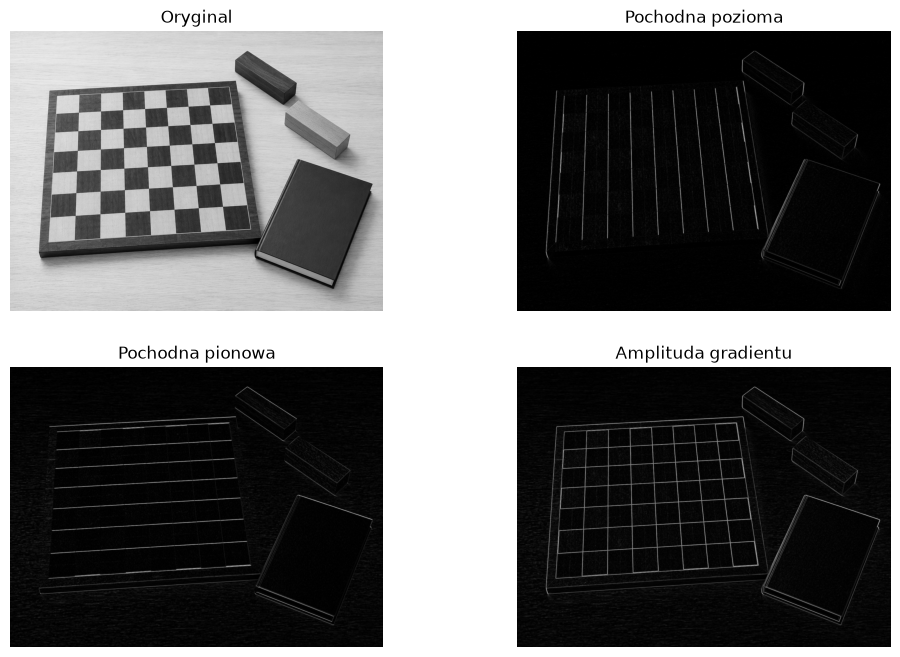

In [2]:
sobel_x = cv2.Sobel(naroza_szare, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(naroza_szare, cv2.CV_64F, 0, 1, ksize=3)

abs_x = np.absolute(sobel_x)
abs_y = np.absolute(sobel_y)
amplituda = np.sqrt(sobel_x**2 + sobel_y**2)

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(naroza_szare, cmap="gray")
plt.title("Oryginal")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(abs_x, cmap="gray")
plt.title("Pochodna pozioma")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(abs_y, cmap="gray")
plt.title("Pochodna pionowa")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(amplituda, cmap="gray")
plt.title("Amplituda gradientu")
plt.axis("off")
plt.show()

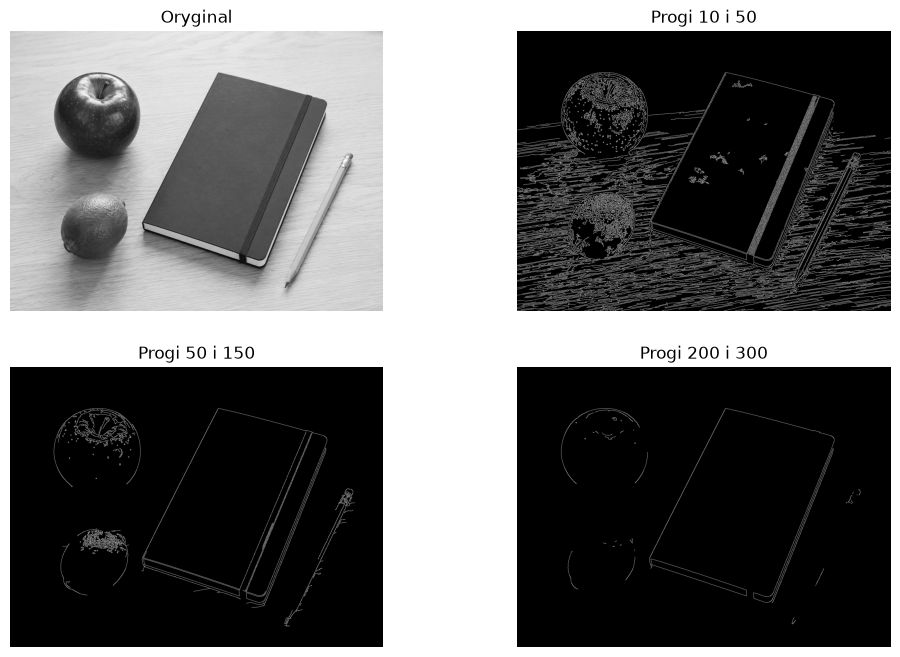

In [3]:
rozmyty = cv2.GaussianBlur(szary, (5, 5), 0)

pary_progow = [(10, 50), (50, 150), (200, 300)]

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(szary, cmap="gray")
plt.title("Oryginal")
plt.axis("off")

for i, (dolny, gorny) in enumerate(pary_progow):
    krawedzie = cv2.Canny(rozmyty, dolny, gorny)
    plt.subplot(2, 2, i + 2)
    plt.imshow(krawedzie, cmap="gray")
    plt.title(f"Progi {dolny} i {gorny}")
    plt.axis("off")

plt.show()

Liczba wykrytych odcinkow: 17


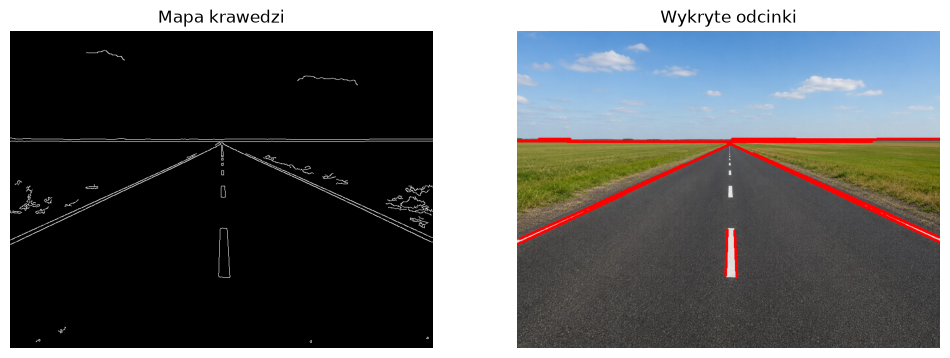

In [4]:
droga = cv2.imread("obraz_droga.jpg")
droga_rgb = cv2.cvtColor(droga, cv2.COLOR_BGR2RGB)
droga_szara = cv2.cvtColor(droga, cv2.COLOR_BGR2GRAY)

rozmyta = cv2.GaussianBlur(droga_szara, (5, 5), 0)
krawedzie_drogi = cv2.Canny(rozmyta, 50, 150)

linie = cv2.HoughLinesP(
    krawedzie_drogi, 1, np.pi / 180, threshold=80, minLineLength=60, maxLineGap=10
)

z_liniami = droga_rgb.copy()
if linie is not None:
    print("Liczba wykrytych odcinkow:", len(linie))
    for linia in linie:
        x1, y1, x2, y2 = map(int, linia.flatten())
        cv2.line(z_liniami, (x1, y1), (x2, y2), (255, 0, 0), 3)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(krawedzie_drogi, cmap="gray")
plt.title("Mapa krawedzi")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(z_liniami)
plt.title("Wykryte odcinki")
plt.axis("off")
plt.show()

Liczba wykrytych monet: 8


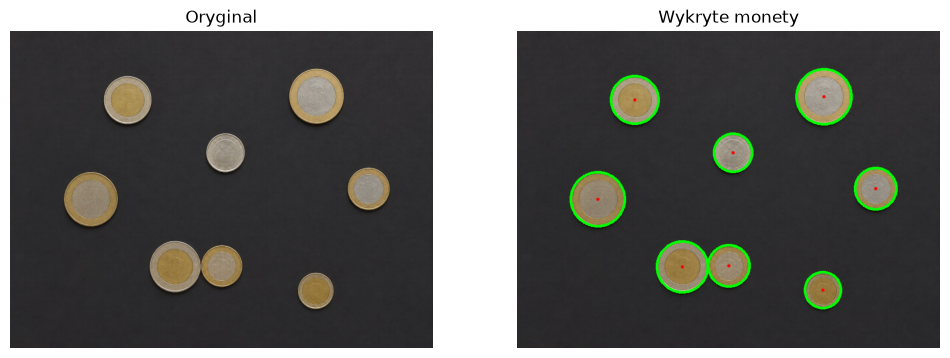

In [5]:
monety = cv2.imread("obraz_monety.jpg")
monety_rgb = cv2.cvtColor(monety, cv2.COLOR_BGR2RGB)
monety_szare = cv2.cvtColor(monety, cv2.COLOR_BGR2GRAY)

rozmyte = cv2.medianBlur(monety_szare, 7)

okregi = cv2.HoughCircles(
    rozmyte,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=60,
    param1=120,
    param2=40,
    minRadius=25,
    maxRadius=90,
)

z_okregami = monety_rgb.copy()
if okregi is not None:
    okregi = np.uint16(np.around(okregi))
    print("Liczba wykrytych monet:", okregi.shape[1])
    for okrag in okregi[0]:
        x, y, r = okrag
        cv2.circle(z_okregami, (x, y), r, (0, 255, 0), 3)
        cv2.circle(z_okregami, (x, y), 3, (255, 0, 0), -1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(monety_rgb)
plt.title("Oryginal")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(z_okregami)
plt.title("Wykryte monety")
plt.axis("off")
plt.show()

# ZADANIE 1

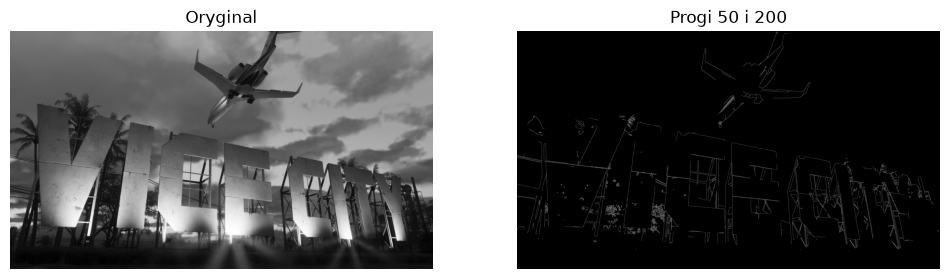

In [6]:
obraz = cv2.imread("screenshot_lab_6.jpg")
szary = cv2.cvtColor(obraz, cv2.COLOR_BGR2GRAY)

rozmyty = cv2.GaussianBlur(szary, (5, 5), 0)

pary_progow = [(50, 200)]

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(szary, cmap="gray")
plt.title("Oryginal")
plt.axis("off")

for i, (dolny, gorny) in enumerate(pary_progow):
    krawedzie = cv2.Canny(rozmyty, dolny, gorny)
    plt.subplot(2, 2, i + 2)
    plt.imshow(krawedzie, cmap="gray")
    plt.title(f"Progi {dolny} i {gorny}")
    plt.axis("off")

plt.show()

# Zadanie 2

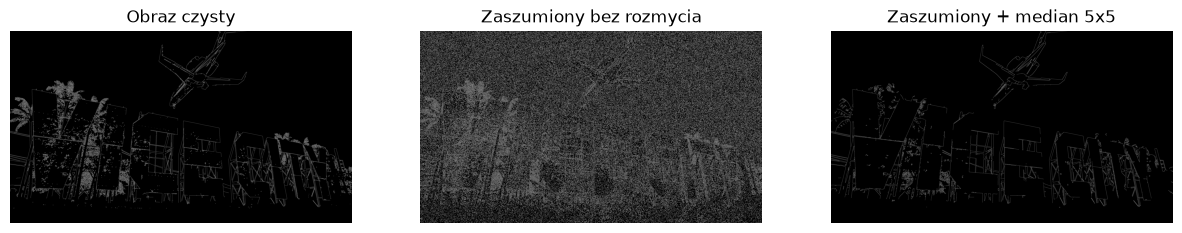

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

obraz = cv2.imread("screenshot_lab_6.jpg")
obraz_rgb = cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)

zaszumiony = obraz_rgb.copy()
wys, szer = zaszumiony.shape[:2]
ile = int(0.02 * wys * szer)
ys = np.random.randint(0, wys, ile)
xs = np.random.randint(0, szer, ile)
zaszumiony[ys, xs] = [255, 255, 255]
ys = np.random.randint(0, wys, ile)
xs = np.random.randint(0, szer, ile)
zaszumiony[ys, xs] = [0, 0, 0]

po_medianie = cv2.medianBlur(zaszumiony, 5)

czysty = cv2.cvtColor(obraz_rgb, cv2.COLOR_RGB2GRAY)
szum = cv2.cvtColor(zaszumiony, cv2.COLOR_RGB2GRAY)
med = cv2.cvtColor(po_medianie, cv2.COLOR_RGB2GRAY)

wyniki = [
    ("Obraz czysty", cv2.Canny(czysty, 50, 150)),
    ("Zaszumiony bez rozmycia", cv2.Canny(szum, 50, 150)),
    ("Zaszumiony + median 5x5", cv2.Canny(med, 50, 150)),
]

plt.figure(figsize=(15, 5))
for i, (tytul, k) in enumerate(wyniki):
    plt.subplot(1, 3, i + 1)
    plt.imshow(k, cmap="gray")
    plt.title(tytul)
    plt.axis("off")
plt.show()

# Zadanie 3

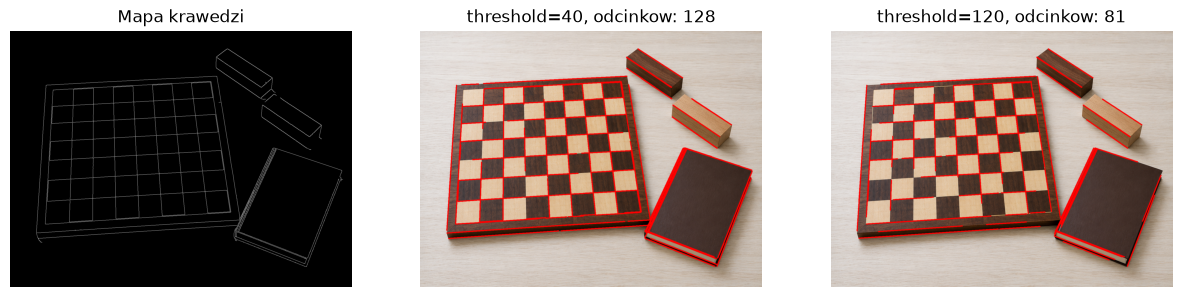

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

naroza = cv2.imread("obraz_naroza.jpg")
naroza_rgb = cv2.cvtColor(naroza, cv2.COLOR_BGR2RGB)
naroza_szara = cv2.cvtColor(naroza, cv2.COLOR_BGR2GRAY)

rozmyta = cv2.GaussianBlur(naroza_szara, (5, 5), 0)
krawedzie = cv2.Canny(rozmyta, 50, 150)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(krawedzie, cmap="gray")
plt.title("Mapa krawedzi")
plt.axis("off")

for i, prog in enumerate([40, 120]):
    linie = cv2.HoughLinesP(
        krawedzie, 1, np.pi / 180, threshold=prog, minLineLength=60, maxLineGap=10
    )
    z_liniami = naroza_rgb.copy()
    n = 0
    if linie is not None:
        n = len(linie)
        for linia in linie:
            x1, y1, x2, y2 = map(int, linia.flatten())
            cv2.line(z_liniami, (x1, y1), (x2, y2), (255, 0, 0), 3)
    plt.subplot(1, 3, i + 2)
    plt.imshow(z_liniami)
    plt.title(f"threshold={prog}, odcinkow: {n}")
    plt.axis("off")

plt.show()

# Zadanie 4

param2=15: 8
param2=40: 8
param2=60: 2


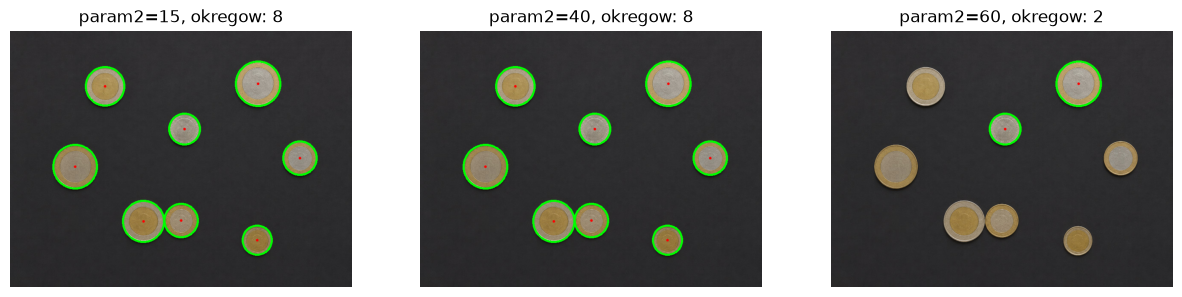

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

monety = cv2.imread("obraz_monety.jpg")
monety_rgb = cv2.cvtColor(monety, cv2.COLOR_BGR2RGB)
monety_szare = cv2.cvtColor(monety, cv2.COLOR_BGR2GRAY)
rozmyte = cv2.medianBlur(monety_szare, 7)

plt.figure(figsize=(15, 5))
for i, p2 in enumerate([15, 40, 60]):
    okregi = cv2.HoughCircles(
        rozmyte,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=60,
        param1=120,
        param2=p2,
        minRadius=25,
        maxRadius=90,
    )
    wynik = monety_rgb.copy()
    n = 0
    if okregi is not None:
        okregi = np.uint16(np.around(okregi))
        n = okregi.shape[1]
        for x, y, r in okregi[0]:
            cv2.circle(wynik, (int(x), int(y)), int(r), (0, 255, 0), 3)
            cv2.circle(wynik, (int(x), int(y)), 3, (255, 0, 0), -1)
    print(f"param2={p2}: {n}")
    plt.subplot(1, 3, i + 1)
    plt.imshow(wynik)
    plt.title(f"param2={p2}, okregow: {n}")
    plt.axis("off")
plt.show()

param2=10: 256
param2=30: 15


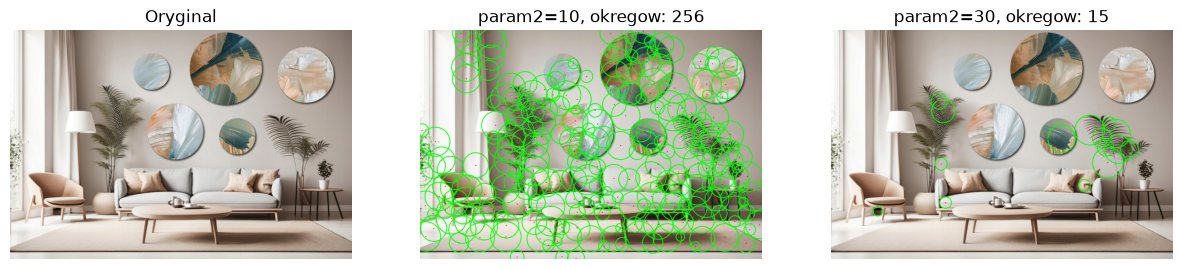

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

moje = cv2.imread("lab6_okragle.jpg")
moje_rgb = cv2.cvtColor(moje, cv2.COLOR_BGR2RGB)
moje_szare = cv2.cvtColor(moje, cv2.COLOR_BGR2GRAY)
rozmyte = cv2.medianBlur(moje_szare, 7)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(moje_rgb)
plt.title("Oryginal")
plt.axis("off")

for i, p2 in enumerate([10, 30]):
    okregi = cv2.HoughCircles(
        rozmyte,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=60,
        param1=120,
        param2=p2,
        minRadius=25,
        maxRadius=90,
    )
    wynik = moje_rgb.copy()
    n = 0
    if okregi is not None:
        okregi = np.uint16(np.around(okregi))
        n = okregi.shape[1]
        for x, y, r in okregi[0]:
            cv2.circle(wynik, (int(x), int(y)), int(r), (0, 255, 0), 3)
            cv2.circle(wynik, (int(x), int(y)), 3, (255, 0, 0), -1)
    print(f"param2={p2}: {n}")
    plt.subplot(1, 3, i + 2)
    plt.imshow(wynik)
    plt.title(f"param2={p2}, okregow: {n}")
    plt.axis("off")
plt.show()

Liczba wykrytych monet: 8
Moneta 1: promien = 36
Moneta 2: promien = 48
Moneta 3: promien = 52
Moneta 4: promien = 39
Moneta 5: promien = 51
Moneta 6: promien = 45
Moneta 7: promien = 39
Moneta 8: promien = 34


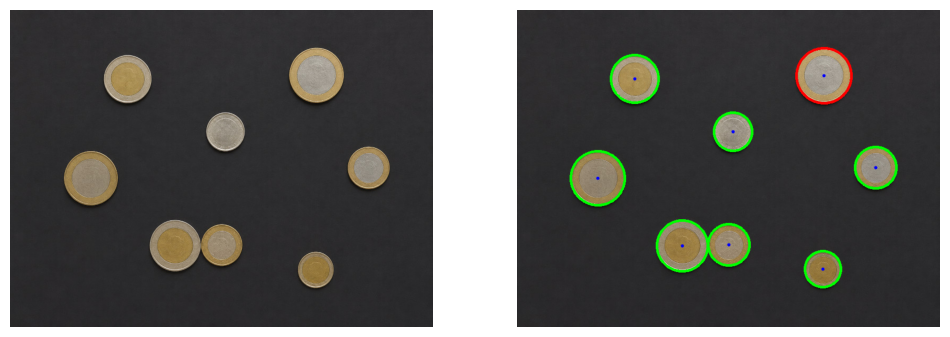

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

monety = cv2.imread("obraz_monety.jpg")
monety_rgb = cv2.cvtColor(monety, cv2.COLOR_BGR2RGB)
monety_szare = cv2.cvtColor(monety, cv2.COLOR_BGR2GRAY)
rozmyte = cv2.medianBlur(monety_szare, 7)

okregi = cv2.HoughCircles(
    rozmyte,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=60,
    param1=120,
    param2=40,
    minRadius=25,
    maxRadius=90,
)

wynik = monety_rgb.copy()
if okregi is not None:
    okregi = np.uint16(np.around(okregi))[0]
    najwiekszy = max(range(len(okregi)), key=lambda i: okregi[i][2])
    print("Liczba wykrytych monet:", len(okregi))
    for i, (x, y, r) in enumerate(okregi):
        print(f"Moneta {i + 1}: promien = {r}")
        kolor = (255, 0, 0) if i == najwiekszy else (0, 255, 0)
        cv2.circle(wynik, (int(x), int(y)), int(r), kolor, 3)
        cv2.circle(wynik, (int(x), int(y)), 3, (0, 0, 255), -1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(monety_rgb)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(wynik)
plt.axis("off")
plt.show()

# Zadanie dodatkowe

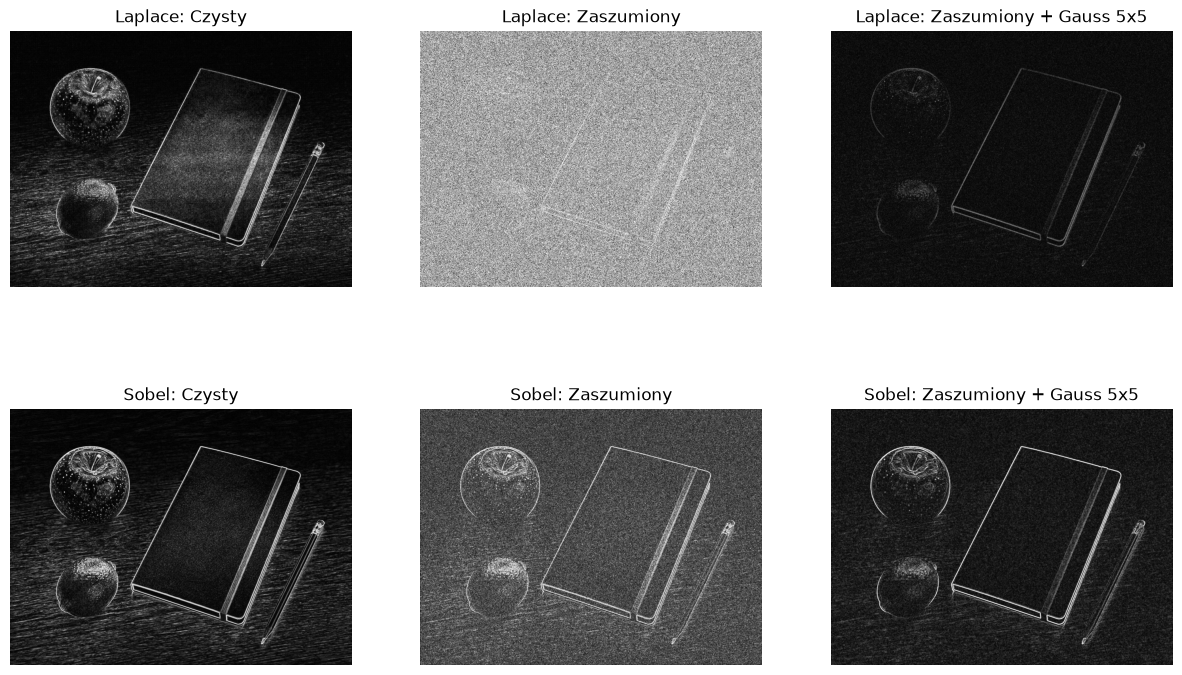

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

obraz = cv2.imread("obraz_testowy.jpg")
szary = cv2.cvtColor(obraz, cv2.COLOR_BGR2GRAY)

zaszumiony = np.clip(szary + np.random.normal(0, 15, szary.shape), 0, 255).astype(
    np.uint8
)
rozmyty = cv2.GaussianBlur(zaszumiony, (5, 5), 0)


def laplace(im):
    return np.absolute(cv2.Laplacian(im, cv2.CV_64F))


def sobel(im):
    sx = cv2.Sobel(im, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(im, cv2.CV_64F, 0, 1, ksize=3)
    return np.sqrt(sx**2 + sy**2)


obrazy = [
    ("Czysty", szary),
    ("Zaszumiony", zaszumiony),
    ("Zaszumiony + Gauss 5x5", rozmyty),
]

plt.figure(figsize=(15, 9))
for r, (nazwa, f) in enumerate([("Laplace", laplace), ("Sobel", sobel)]):
    vmax = np.percentile(f(szary), 99)
    for c, (tytul, im) in enumerate(obrazy):
        plt.subplot(2, 3, r * 3 + c + 1)
        plt.imshow(f(im), cmap="gray", vmin=0, vmax=vmax)
        plt.title(f"{nazwa}: {tytul}")
        plt.axis("off")
plt.show()